In [28]:
import sys

print(sys.executable)
print(sys.version)

/opt/conda/envs/mlops/bin/python
3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:21:38) [GCC 14.3.0]


In [29]:
%pip install pandas pyarrow scikit-learn matplotlib seaborn jupyterlab xgboost

Note: you may need to restart the kernel to use updated packages.


In [30]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

In [31]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("../data")
data_dir.mkdir(exist_ok=True)

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"
file_path = data_dir / "yellow_tripdata_2026-05.parquet"

if not file_path.exists():
    urlretrieve(url, file_path)

file_path

PosixPath('../data/yellow_tripdata_2026-05.parquet')

In [32]:
!pwd

/workspaces/learning-mlops/notebooks


In [33]:
data_path = Path("/workspaces/learning-mlops/data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvablµe : {data_path}")

data_path

PosixPath('/workspaces/learning-mlops/data/yellow_tripdata_2026-05.parquet')

In [34]:
df = pd.read_parquet(data_path)
df.shape

(1369769, 19)

In [35]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2021-01-01 00:30:10,2021-01-01 00:36:12,142,43,2.10
1,2021-01-01 00:51:20,2021-01-01 00:52:19,238,151,0.20
2,2021-01-01 00:43:30,2021-01-01 01:11:06,132,165,14.70
3,2021-01-01 00:15:48,2021-01-01 00:31:01,138,132,10.60
4,2021-01-01 00:31:49,2021-01-01 00:48:21,68,33,4.94


In [36]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    1.369769e+06
mean     1.391168e+01
std      1.312006e+02
min     -1.350846e+05
25%      5.566667e+00
50%      9.066667e+00
75%      1.461667e+01
max      2.881770e+04
Name: duration, dtype: float64

In [37]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(1343254, 21)

In [38]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

In [39]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

In [40]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12500), (40000, 12500))

In [41]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

4.8534189177959774

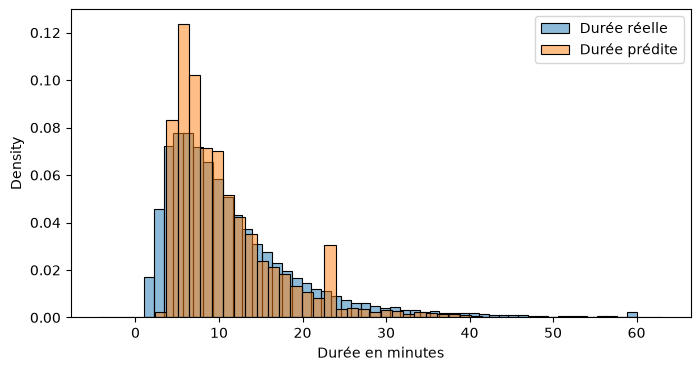

In [42]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)
plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

In [44]:
import numpy as np

# Convertir les matrices sparse en format CSC
X_train = X_train.tocsc()
X_val = X_val.tocsc()

# Convertir les indices de 64 bits en 32 bits
X_train.indices = X_train.indices.astype(np.int32)
X_train.indptr = X_train.indptr.astype(np.int32)

X_val.indices = X_val.indices.astype(np.int32)
X_val.indptr = X_val.indptr.astype(np.int32)

In [57]:
lasso_model = Lasso(alpha=0.1, max_iter=10_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

8.780912844940385

In [58]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

4.351969735010792

In [59]:
results = pd.DataFrame(
    {
        "model": ["LinearRegression", "Lasso", "XGBoost"],
        "rmse": [linear_rmse, lasso_rmse, xgb_rmse],
    }
).sort_values("rmse")

results

,model,rmse
2,XGBoost,4.351970
0,LinearRegression,4.853419
1,Lasso,8.780913


In [60]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost', 4.351969735010792, PosixPath('models/duration_model.bin'))

In [61]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
example_matrix = loaded_dv.transform(example)
prediction = loaded_model.predict(example_matrix)[0]

prediction

np.float32(14.94051)

In [62]:
lasso_results = []

for alpha in [0.001, 0.01, 0.1]:

    model = Lasso(alpha=alpha, max_iter=10_000)

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    rmse = root_mean_squared_error(y_val, predictions)

    lasso_results.append({
        "model": "Lasso",
        "alpha": alpha,
        "rmse": rmse
    })

    print(f"Lasso alpha={alpha} | RMSE={rmse:.4f}")

Lasso alpha=0.001 | RMSE=6.6129
Lasso alpha=0.01 | RMSE=8.5840
Lasso alpha=0.1 | RMSE=8.7809


In [63]:
xgb_model = XGBRegressor(
    max_depth=6,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)

xgb_rmse = root_mean_squared_error(
    y_val,
    xgb_predictions
)

print(f"XGBoost max_depth=6 | RMSE={xgb_rmse:.4f}")

XGBoost max_depth=6 | RMSE=4.3520


In [64]:
lasso_results.append({
    "model": "XGBoost",
    "alpha": None,
    "rmse": xgb_rmse
})

results_df = pd.DataFrame(lasso_results)

results_df = results_df.sort_values("rmse")

display(results_df)

,model,alpha,rmse
3,XGBoost,NaN,4.351970
0,Lasso,0.001,6.612852
1,Lasso,0.010,8.583990
2,Lasso,0.100,8.780913


In [ ]:
Modèle retenu : [XGBoost]

Le modèle a été retenu car il présente la RMSE de validation la plus faible parmi les différentes expériences réalisées. Ses prédictions sont donc globalement plus proches des durées réelles des trajets.

Il faudra également vérifier qu'il ne présente pas de surapprentissage en comparant ses performances sur les données d'entraînement et de validation.

Information	Exemple
Nom du modèle	Lasso
Hyperparamètres	alpha=0.01
Données utilisées	X_train, y_train
Jeu de validation	X_val, y_val
RMSE	7.25
Version de Python	3.12
Version de Scikit-learn	Version utilisée
Version de XGBoost	Version utilisée
Random state	42
Prétraitement	DictVectorizer
Date de l'expérience	Date et heure
Modèle entraîné	Fichier du modèle sauvegardé
Code source	Version ou commit Git